In [19]:
import sys
sys.path.append("..")          
import numpy as np
import pandas as pd
import matplotlib.pyplot as pt
import seaborn as sn

from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_iterative_imputer  
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

from src.transformers import IQRClipper

## preparation des donnees

In [ ]:
data = pd.read_csv("../data/orig/student_mental_health.csv")

cible = "Mental_Health_Risk"
quant_discretes = ["Age", "Year_of_Study"]
quant_continues = ["Sleep_Hours", "Study_Hours_Per_Week", "GPA",
                   "Social_Media_Hours", "Screen_Time_Hours",
                   "Financial_Stress", "Family_Support", "Attendance_Rate"]
qualitatives = ["Gender", "Physical_Activity", "Part_Time_Job",
                "Diet_Quality", "Previous_Mental_Health_History"]

ordreRisque = {"Low": 0, "Medium": 1, "High": 2}
labelsRisque = list(ordreRisque)


Train : (1600, 15)  Test : (400, 15)


## qualite de data 

In [86]:
colonnesTexte = [c for c in data.columns if pd.api.types.is_string_dtype(data[c])]
espaces = sum((data[c].dropna() != data[c].dropna().str.strip()).sum() for c in colonnesTexte)

print("Lignes dupliquées :", data.duplicated().sum())
print("Student_ID dupliqués :", data["Student_ID"].duplicated().sum())
print("Cible manquante :", data["Mental_Health_Risk"].isnull().sum())
print("Valeurs texte avec espaces parasites :", espaces)

plagesValides = {"Age": (16, 40), "Year_of_Study": (1, 5), "Sleep_Hours": (2, 12),
                 "Study_Hours_Per_Week": (0, 80), "GPA": (0, 4),
                 "Social_Media_Hours": (0, 16), "Screen_Time_Hours": (0, 18),
                 "Financial_Stress": (1, 10), "Family_Support": (1, 10),
                 "Attendance_Rate": (0, 100)}

horsPlage = {col: int((data[col].notna() & data[col].between(bas, haut)).sum())
             for col, (bas, haut) in plagesValides.items()}
horsPlage

Lignes dupliquées : 0
Student_ID dupliqués : 0
Cible manquante : 0
Valeurs texte avec espaces parasites : 0


{'Age': 2000,
 'Year_of_Study': 2000,
 'Sleep_Hours': 1938,
 'Study_Hours_Per_Week': 2000,
 'GPA': 1962,
 'Social_Media_Hours': 1942,
 'Screen_Time_Hours': 2000,
 'Financial_Stress': 1909,
 'Family_Support': 1946,
 'Attendance_Rate': 1953}

In [87]:
X = data.drop(columns=["Student_ID", cible])
y = data[cible].map(ordreRisque)                   

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train :", X_train.shape, " Test :", X_test.shape)

Train : (1600, 15)  Test : (400, 15)


In [91]:
repartitionClasses = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),}).round(3)
repartitionClasses.index = labelsRisque
repartitionClasses

,train,test
Low,0.33,0.33
Medium,0.33,0.33
High,0.34,0.34


###  Traitement des valeurs manquantes

In [92]:
valeursManquantes = X_train.isnull().sum()
valeursManquantes[valeursManquantes > 0].sort_values(ascending=False)

Financial_Stress      71
Diet_Quality          53
Sleep_Hours           49
Social_Media_Hours    49
Family_Support        40
Attendance_Rate       34
GPA                   27
dtype: int64

In [93]:

colonnesIteratives = ["GPA", "Social_Media_Hours", "Screen_Time_Hours",
                      "Study_Hours_Per_Week", "Year_of_Study"]

colonnesMediane = ["Sleep_Hours", "Financial_Stress", "Family_Support",
                   "Attendance_Rate", "Age"]



imputation = ColumnTransformer(
    transformers=[
        ("iteratif", IterativeImputer(max_iter=10, random_state=42), colonnesIteratives),
        ("mediane", SimpleImputer(strategy="median"), colonnesMediane),
    ],remainder="passthrough",verbose_feature_names_out=False,  
)

print(data.isna().sum())

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


###  traitement des valeurs aberrantes 

In [94]:
lignes = []
for col in quant_continues:
    s = X_train[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    masque = (s < inf) | (s > sup)
    lignes.append({"variable": col, "Inf": round(inf, 2), "Sup": round(sup, 2),
                   "nbrAberrantes": int(masque.sum()), "pourcentage": round(masque.mean() * 100, 2)})

tableauAberrantes = pd.DataFrame(lignes)
tableauAberrantes

,variable,Inf,Sup,nbrAberrantes,pourcentage
0,Sleep_Hours,3.75,9.75,8,0.52
1,Study_Hours_Per_Week,3.60,36.40,4,0.25
2,GPA,1.64,3.48,6,0.38
3,Social_Media_Hours,3.12,8.93,17,1.10
4,Screen_Time_Hours,3.95,13.15,6,0.38
5,Financial_Stress,0.00,12.00,0,0.00
6,Family_Support,1.00,12.20,0,0.00
7,Attendance_Rate,66.25,104.25,8,0.51


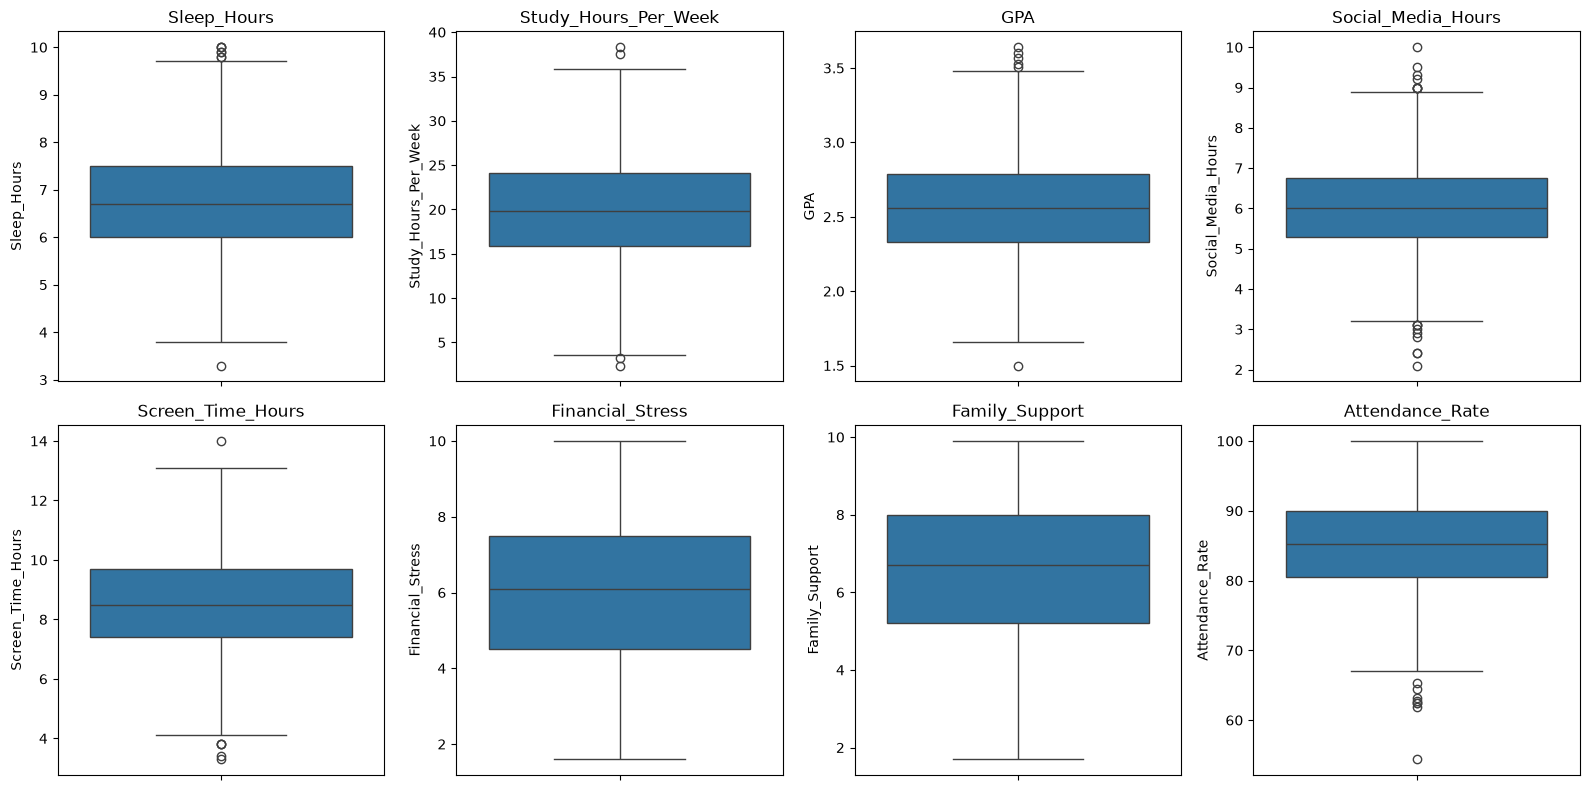

In [95]:
pt.figure(figsize=(16, 8))
for i, col in enumerate(quant_continues, 1):
    pt.subplot(2, 4, i)
    sn.boxplot(y=X_train[col])
    pt.title(col)
pt.tight_layout()
pt.show()

### Encodage des variables categorielles

In [96]:
colonnesOrdinales = ["Physical_Activity", "Diet_Quality"]
colonnesNominales = [c for c in qualitatives if c not in colonnesOrdinales]


pipelineNominal = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

ordreOrdinal = [["Low", "Moderate", "High"],        
                ["Poor", "Average", "Good"]]       

pipelineOrdinal = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OrdinalEncoder(categories=ordreOrdinal,
                                handle_unknown="use_encoded_value", unknown_value=-1)),
])

### Gestion du desequilibre des classes

In [98]:
repartitionClasses = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(3)
repartitionClasses.index = labelsRisque
repartitionClasses

,train,test
Low,0.33,0.33
Medium,0.33,0.33
High,0.34,0.34


pas de SMOTE. Les classes sont équilibrées dans le train 


### standardisation des variables numériques

In [99]:
pipelineContinues = Pipeline([
    ("clipping", IQRClipper(factor=1.5)),           
    ("standardisation", StandardScaler()),
])

transformation = ColumnTransformer(
    transformers=[
        ("continues", pipelineContinues, quant_continues),
        ("discretes", StandardScaler(), quant_discretes),
        ("nominal", pipelineNominal, colonnesNominales),
        ("ordinal", pipelineOrdinal, colonnesOrdinales),
    ],
    remainder="drop",
)

### Regroupement dans un Pipeline 

In [100]:
pretraitement = Pipeline([
    ("imputation", imputation),
    ("transformation", transformation),
]).set_output(transform="pandas")       

XTrainPrepare = pretraitement.fit_transform(X_train)   
XTestPrepare = pretraitement.transform(X_test)        

print("Train :", XTrainPrepare.shape, " manquants :", XTrainPrepare.isna().sum().sum())
print("Test  :", XTestPrepare.shape, " manquants :", XTestPrepare.isna().sum().sum())
XTrainPrepare.head()


Train : (1600, 19)  manquants : 0
Test  : (400, 19)  manquants : 0


,continues__Sleep_Hours,continues__Study_Hours_Per_Week,continues__GPA,continues__Social_Media_Hours,continues__Screen_Time_Hours,continues__Financial_Stress,continues__Family_Support,continues__Attendance_Rate,discretes__Age,discretes__Year_of_Study,nominal__Gender_Female,nominal__Gender_Male,nominal__Gender_Non-binary,nominal__Part_Time_Job_No,nominal__Part_Time_Job_Yes,nominal__Previous_Mental_Health_History_No,nominal__Previous_Mental_Health_History_Yes,ordinal__Physical_Activity,ordinal__Diet_Quality
521,-0.041768,-1.464070,-0.851885,-0.091913,-0.090513,-0.259617,-0.021546,-0.529229,0.416561,-1.224199,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
1393,1.231159,-1.377690,-1.696815,-0.718194,-0.393108,0.657234,-1.233064,-1.180699,-0.058152,-1.224199,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
1710,-0.496385,0.729989,-0.338892,0.087024,0.635713,0.225775,0.694351,1.569952,0.891274,1.058690,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,2.0
555,0.412849,-0.116538,-0.248364,0.355430,-0.211551,-0.637144,-0.627305,-0.920111,-0.532865,-0.463236,0.0,1.0,0.0,0.0,1.0,1.0,0.0,2.0,1.0
523,-0.314538,0.142603,-1.213998,-0.360319,-0.029995,1.304423,1.189972,-2.671841,0.416561,1.058690,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,2.0


In [101]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

## Entrainement


###  Modeles

In [102]:
modeles = {
    "L.Regression": LogisticRegression(max_iter=2000),
    "R.N.C": RandomForestClassifier(n_estimators=200, random_state=42),
}

pipelines = {
    nom: Pipeline([("pretraitement", clone(pretraitement)), ("modele", modele)])
    for nom, modele in modeles.items()
}

### validation croisee (5 )

In [103]:
V_croise = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

predictions = {}
for nom, pipe in pipelines.items():
   
    probabilites = cross_val_predict(pipe, X_train, y_train, cv=V_croise, method="predict_proba")
    predictions[nom] = {"proba": probabilites, "classe": probabilites.argmax(axis=1)}

print("Predictions calculees pour :", list(predictions))

Predictions calculees pour : ['L.Regression', 'R.N.C']


### Metriques 

In [52]:
lignes = []
for nom, p in predictions.items():
    lignes.append({
        "modele": nom,
        "accuracy": accuracy_score(y_train, p["classe"]),
        "precision": precision_score(y_train, p["classe"], average="macro"),
        "recall": recall_score(y_train, p["classe"], average="macro"),
        "f1": f1_score(y_train, p["classe"], average="macro"),
        "roc_auc": roc_auc_score(y_train, p["proba"], multi_class="ovr", average="macro"),
    })

tableauMetriques = pd.DataFrame(lignes).set_index("modele").round(3)
tableauMetriques

,accuracy,precision,recall,f1,roc_auc
modele,,,,,
L.Regression,0.758,0.757,0.757,0.757,0.907
R.N.C,0.706,0.700,0.705,0.702,0.859


*Précision, rappel et F1 sont des moyennes **macro** : les 3 classes comptent de la même façon (les classes sont équilibrées). Le ROC-AUC est calculé en one-vs-rest.*

In [55]:
for nom, p in predictions.items():
    print(f" {nom} ")
    print(classification_report(y_train, p["classe"], target_names=labelsRisque, digits=3))

 L.Regression 
              precision    recall  f1-score   support

         Low      0.819     0.816     0.818       528
      Medium      0.638     0.638     0.638       528
        High      0.813     0.816     0.815       544

    accuracy                          0.757      1600
   macro avg      0.757     0.757     0.757      1600
weighted avg      0.758     0.757     0.758      1600

 R.N.C 
              precision    recall  f1-score   support

         Low      0.762     0.790     0.776       528
      Medium      0.588     0.538     0.562       528
        High      0.751     0.787     0.768       544

    accuracy                          0.706      1600
   macro avg      0.700     0.705     0.702      1600
weighted avg      0.701     0.706     0.703      1600



### 3.4 Matrice de confusion de chaque modèle

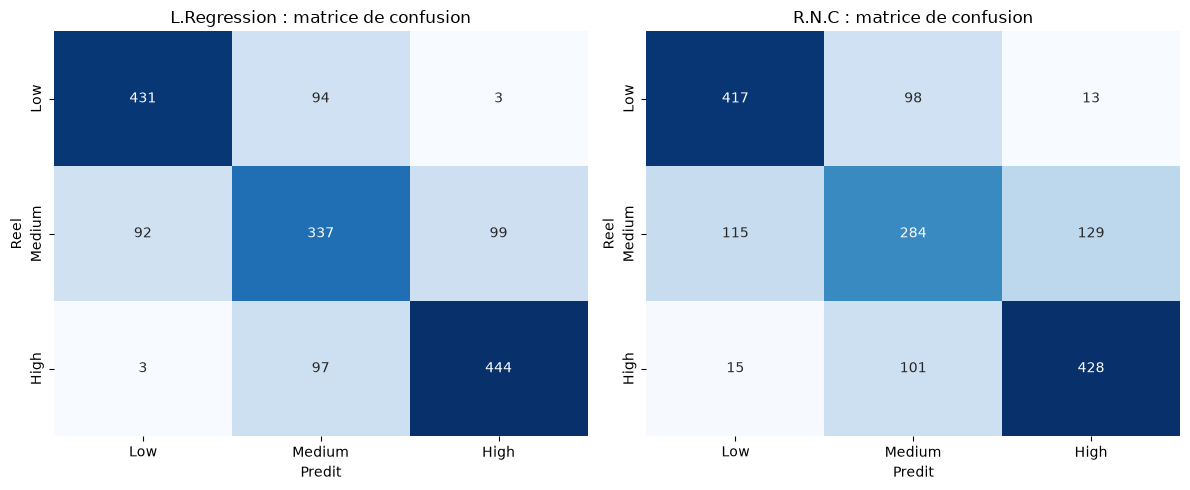

In [113]:
fig, axes = pt.subplots(1, 2, figsize=(12, 5))
for ax, (nom, p) in zip(axes, predictions.items()):
    matrice = confusion_matrix(y_train, p["classe"])

    sn.heatmap(matrice, annot=True, fmt="d", cmap="Blues", ax=ax,
               xticklabels=labelsRisque, yticklabels=labelsRisque, cbar=False)
    ax.set_title(f"{nom} : matrice de confusion")
    ax.set_xlabel("Predit")
    ax.set_ylabel("Reel")

pt.tight_layout()
pt.show()

### Courbes ROC et AUC

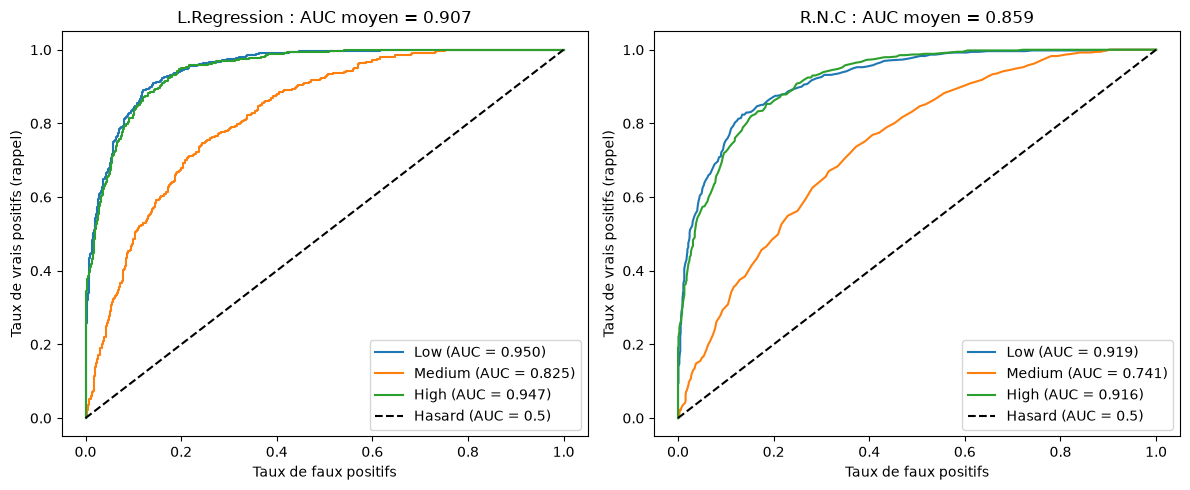

In [109]:
yBinaire = label_binarize(y_train, classes=[0, 1, 2])      

fig, axes = pt.subplots(1, 2, figsize=(12, 5))
for ax, (nom, p) in zip(axes, predictions.items()):
    for i, classe in enumerate(labelsRisque):
        fpr, tpr, _ = roc_curve(yBinaire[:, i], p["proba"][:, i])
        auc = roc_auc_score(yBinaire[:, i], p["proba"][:, i])
        ax.plot(fpr, tpr, label=f"{classe} (AUC = {auc:.3f})")

    ax.plot([0, 1], [0, 1], "k--", label="Hasard (AUC = 0.5)")
    ax.set_title(f"{nom} : AUC moyen = {tableauMetriques.loc[nom, 'roc_auc']:.3f}")
    ax.set_xlabel("Taux de faux positifs")
    ax.set_ylabel("Taux de vrais positifs (rappel)")
    ax.legend(loc="lower right")
pt.tight_layout()
pt.show()

### Entrainement final sur tout le train

In [115]:
resume = []
for nom, pipe in pipelines.items():
    pipe.fit(X_train, y_train)                                
    resume.append({
        "modele": nom,
        "accuracy train": round(pipe.score(X_train, y_train), 3),
        "accuracy validation croisee": tableauMetriques.loc[nom, "accuracy"],
    })

resume = pd.DataFrame(resume).set_index("modele")

resume

,accuracy train,accuracy validation croisee
modele,,
L.Regression,0.767,0.758
R.N.C,1.000,0.706


### 
- Meilleur modele : 